In [6]:
import zipfile

zip_path = "happy.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("happy")

print("ZIP file extracted successfully!")

ZIP file extracted successfully!


In [7]:
# import necessary modules
import os
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam

In [8]:
dataset_path = r"C:\Users\pente\Downloads\happy"

Angry_dir = os.path.join(dataset_path, "angry")
Happy_dir = os.path.join(dataset_path, "happy")
Neutral_dir = os.path.join(dataset_path, "neutral")
Sad_dir = os.path.join(dataset_path, "sad")
Surprise_dir = os.path.join(dataset_path, "surprise")

print("Angry:", os.path.exists(Angry_dir))
print("Happy:", os.path.exists(Happy_dir))
print("Neutral:", os.path.exists(Neutral_dir))
print("Sad:", os.path.exists(Sad_dir))
print("Surprise:", os.path.exists(Surprise_dir))

Angry: True
Happy: True
Neutral: True
Sad: True
Surprise: True


In [9]:
IMG_SIZE = 48
batch_size = 32
num_classes = 5

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

In [10]:
train_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=(48, 48),
    batch_size=batch_size,
    color_mode="grayscale",
    classes=[
        "angry",
        "happy",
        "neutral",
        "sad",
        "surprise"
    ],
    class_mode="categorical",
    shuffle=True
)

print("\nClass indices:")
print(train_generator.class_indices)

print("\nTotal training images:", train_generator.samples)

Found 24282 images belonging to 5 classes.

Class indices:
{'angry': 0, 'happy': 1, 'neutral': 2, 'sad': 3, 'surprise': 4}

Total training images: 24282



CNN Model:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 46, 46, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 23, 23, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 21, 21, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 10, 10, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 8, 8, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 4, 4, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         262,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 355,589 (1.36 MB)

 Trainable params: 355,589 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
759/759 ━━━━━━━━━━━━━━━━━━━━ 46s 59ms/step - accuracy: 0.3102 - loss: 1.5421
Epoch 2/5
759/759 ━━━━━━━━━━━━━━━━━━━━ 33s 43ms/step - accuracy: 0.3806 - loss: 1.4375
Epoch 3/5
759/759 ━━━━━━━━━━━━━━━━━━━━ 35s 47ms/step - accuracy: 0.4596 - loss: 1.3036
Epoch 4/5
759/759 ━━━━━━━━━━━━━━━━━━━━ 35s 46ms/step - accuracy: 0.4965 - loss: 1.2225
Epoch 5/5
759/759 ━━━━━━━━━━━━━━━━━━━━ 35s 46ms/step - accuracy: 0.5217 - loss: 1.1791



TRAINING COMPLETED SUCCESSFULLY
Model saved as: emotion_model.h5


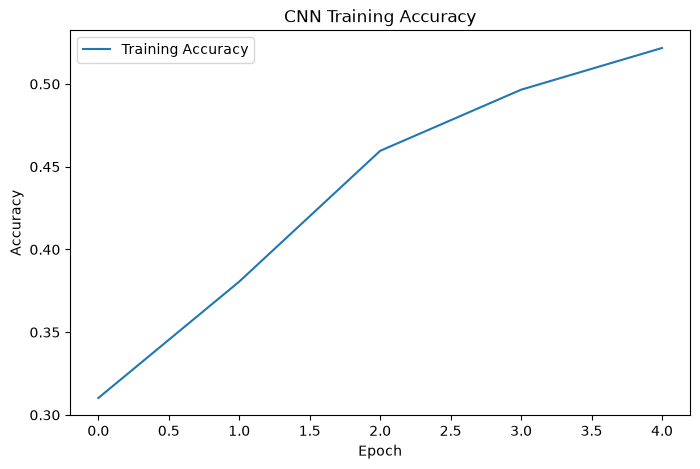

In [11]:
model = Sequential([
    Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(48, 48, 1)
    ),
    MaxPooling2D((2, 2)),

    Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),
    MaxPooling2D((2, 2)),

    Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(
        128,
        activation="relu"
    ),

    Dropout(0.5),

    Dense(
        5,
        activation="softmax"
    )
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nCNN Model:")
model.summary()

history = model.fit(
    train_generator,
    epochs=5,
    verbose=1
)

model.save("emotion_model.h5")

print("\n======================================")
print("TRAINING COMPLETED SUCCESSFULLY")
print("Model saved as: emotion_model.h5")
print("======================================")

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.title("CNN Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

In [12]:
print("Testing image loading...")

x, y = next(train_generator)

print("✅ Batch loaded!")
print("Images:", x.shape)
print("Labels:", y.shape)

Testing image loading...
✅ Batch loaded!
Images: (32, 48, 48, 1)
Labels: (32, 5)


In [13]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

model = load_model("emotion_model.h5")

test_path = r"C:\Users\bhagya2006\Downloads\happy\happy"

print("Model loaded successfully!")

Model loaded successfully!


In [15]:
import os

folder = r"C:\Users\pente\Downloads\happy"

print(os.listdir(folder)[:10])

['angry', 'happy', 'neutral', 'sad', 'surprise']


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
Predicted Emotion: angry
Confidence: 29.15 %


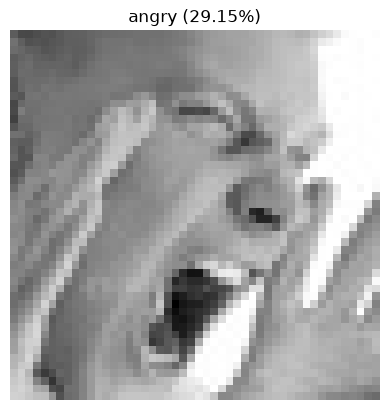

In [18]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

model = load_model("emotion_model.h5")

test_path = r"C:\Users\pente\Downloads\happy\angry\985.jpg"

img = image.load_img(
    test_path,
    target_size=(48, 48),
    color_mode="grayscale"
)

img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

classes = ["angry", "happy", "neutral", "sad", "surprise"]

predicted_class = classes[np.argmax(prediction)]
confidence = np.max(prediction) * 100

print("Predicted Emotion:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

plt.imshow(img, cmap="gray")
plt.title(f"{predicted_class} ({confidence:.2f}%)")
plt.axis("off")
plt.show()

In [19]:
import os
from tensorflow.keras.preprocessing import image
import numpy as np

classes = ["angry", "happy", "neutral", "sad", "surprise"]

for emotion in classes:
    folder = os.path.join(
        r"C:\Users\pente\Downloads\happy",
        emotion
    )

    files = os.listdir(folder)
    test_file = files[0]
    test_path = os.path.join(folder, test_file)

    img = image.load_img(
        test_path,
        target_size=(48, 48),
        color_mode="grayscale"
    )

    img_array = image.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)

    predicted_class = classes[np.argmax(prediction)]
    confidence = np.max(prediction) * 100

    print(
        emotion.upper(),
        "→ Predicted:",
        predicted_class,
        "| Confidence:",
        round(confidence, 2), "%"
    )

ANGRY → Predicted: angry | Confidence: 49.41 %
HAPPY → Predicted: happy | Confidence: 96.51 %
NEUTRAL → Predicted: neutral | Confidence: 37.19 %
SAD → Predicted: neutral | Confidence: 38.8 %
SURPRISE → Predicted: surprise | Confidence: 73.8 %


In [20]:
!pip install opencv-python

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/44.0 MB 345.3 kB/s eta 0:02:06
   ---------------------------------------- 0.5/44.0 MB 345.3 kB/s eta 0:02:06
   ---------------------------------------- 0.5/44.0 MB 345.3 kB/s eta 0:02:06
    --------------------------------------- 0.8/44.0 MB 403.0 kB/s eta 0:01:48
    --------------------------------------- 0.8/44.0 MB 403.0 kB/s eta 0:01:48
    --------------------------------------- 1.0/44.0 MB 439.3 kB/s eta 0:01:38
    --------------------------------------- 1.0/44.0 MB 439.3 kB/s eta 0:01:38
    -----------------------

In [1]:
import cv2

cap = cv2.VideoCapture(0)

if cap.isOpened():
    print("Camera opened successfully!")
else:
    print("Camera could not be opened.")

cap.release()

Camera opened successfully!


In [ ]:
import cv2
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import img_to_array

model = load_model("emotion_model.h5")

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

classes = ["Angry", "Happy", "Neutral", "Sad", "Surprise"]

cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()

    if not ret:
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.3,
        minNeighbors=5
    )

    for (x, y, w, h) in faces:

        roi_gray = gray[y:y+h, x:x+w]
        roi_gray = cv2.resize(roi_gray, (48, 48))

        roi = roi_gray.astype("float") / 255.0
        roi = img_to_array(roi)
        roi = np.expand_dims(roi, axis=0)

        prediction = model.predict(roi, verbose=0)[0]

        label = classes[np.argmax(prediction)]
        confidence = np.max(prediction) * 100

        cv2.rectangle(
            frame,
            (x, y),
            (x+w, y+h),
            (255, 0, 0),
            2
        )

        cv2.putText(
            frame,
            f"{label} {confidence:.1f}%",
            (x, y-10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2
        )

    cv2.imshow("Emotion Detector", frame)

    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()

In [ ]:
import cv2

print(cv2)
print(cv2.__version__)
print(cv2.__file__)

In [ ]:
import cv2

print("OpenCV version:", cv2.__version__)
print("CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))

In [ ]:
import cv2
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import img_to_array

model = load_model("emotion_model.h5")

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

classes = ["Angry", "Happy", "Neutral", "Sad", "Surprise"]

cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()

    if not ret:
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.3,
        minNeighbors=5
    )

    for (x, y, w, h) in faces:

        roi_gray = gray[y:y+h, x:x+w]
        roi_gray = cv2.resize(roi_gray, (48, 48))

        roi = roi_gray.astype("float") / 255.0
        roi = img_to_array(roi)
        roi = np.expand_dims(roi, axis=0)

        prediction = model.predict(roi, verbose=0)[0]

        label = classes[np.argmax(prediction)]
        confidence = np.max(prediction) * 100

        cv2.rectangle(
            frame,
            (x, y),
            (x+w, y+h),
            (255, 0, 0),
            2
        )

        cv2.putText(
            frame,
            f"{label} {confidence:.1f}%",
            (x, y-10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2
        )

    cv2.imshow("Emotion Detector", frame)

    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()

In [ ]:
import cv2

cap = cv2.VideoCapture(0)

ret, frame = cap.read()

print("Camera opened:", cap.isOpened())
print("Frame captured:", ret)
print("Frame shape:", frame.shape if ret else None)

cap.release()